# RH · qualidade de dados e programas de desenvolvimento

Estudo reproduzível de tratamento de dados e recomendação explicável por regras.
A demonstração usa perfis inteiramente sintéticos, gerados com semente fixa.

O fluxo parte de uma fotografia cadastral, verifica sua qualidade, separa o público
com vínculo e simula cinco programas. As regras são hipóteses para discussão com RH.
Cada sugestão apresenta a pontuação, os motivos e os possíveis empates.

## 1. Preparação

Em um clone local, instale `requirements.txt` e execute o notebook de cima para baixo.
No Colab, a primeira célula clona o repositório público quando os arquivos ainda não
estiverem disponíveis. A data de referência é um parâmetro explícito do estudo.

In [1]:
from pathlib import Path
import sys
import subprocess
import json
import platform

candidatos = [Path.cwd(), Path.cwd().parent]
RAIZ = next((p for p in candidatos if (p / 'src/rh_programas.py').exists()), None)
if RAIZ is None and 'google.colab' in sys.modules:
    destino = Path('/content/Projeto-RH')
    if not destino.exists():
        subprocess.run(['git', 'clone', 'https://github.com/Assoridente/Projeto-RH.git', str(destino)], check=True)
    RAIZ = destino
if RAIZ is None:
    raise FileNotFoundError('Abra o notebook dentro do clone do repositório Projeto-RH.')
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.rh_programas import carregar_csv, tratar_base, simular_programas

pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 90)
print(f'Python {platform.python_version()} · pandas {pd.__version__} · NumPy {np.__version__}')

Matplotlib is building the font cache; this may take a moment.


Python 3.10.11 · pandas 2.3.2 · NumPy 2.2.6


In [2]:
DATA_REFERENCIA = '2026-11-09'
ARQUIVO = RAIZ / 'data/sinteticos/base_rh_sintetica.csv'
EXPORTAR_RESULTADOS = False

origem = carregar_csv(ARQUIVO)
display(pd.DataFrame({
    'Medida': ['Linhas recebidas', 'Colunas', 'Data de referência', 'Natureza dos dados'],
    'Valor': [len(origem), len(origem.columns), DATA_REFERENCIA, 'Perfis sintéticos'],
}))
display(origem[['Cód Funcionário', 'Cargo', 'Escolaridade', 'Situação', 'Valor Salário']].head())

,Medida,Valor
0,Linhas recebidas,241
1,Colunas,10
2,Data de referência,2026-11-09
3,Natureza dos dados,Perfis sintéticos


,Cód Funcionário,Cargo,Escolaridade,Situação,Valor Salário
0,SINT-0001,ASSISTENTE ADMINISTRATIVO,Ensino Médio Completo,Trabalhando,"R$ 4.500,00"
1,SINT-0002,AUXILIAR DE PRODUÇÃO,Superior Completo,Trabalhando,18500.0
2,SINT-0003,ANALISTA RECURSOS HUMANOS,Superior Completo,Trabalhando,<NA>
3,SINT-0004,ANALISTA REDES E SISTEMAS PL,Superior Incompleto,Trabalhando,valor inválido
4,SINT-0005,VENDEDOR EM GERAL,Ensino Médio Completo,Trabalhando,"R$ 60.000,00"


## 2. Qualidade antes das recomendações

As colunas recebidas são preservadas. Datas e salário tratados ficam em novas colunas.
Datas ausentes permanecem ausentes. Salários fora dos limites ilustrativos de conferência
são sinalizados, sem receber teto ou mediana.

A escolaridade é agrupada pela descrição. Ensino médio permanece no grupo Médio e
graduação no grupo Superior. Completo e incompleto indicam o nível frequentado e mantêm
sua descrição original. Cargos são associados ao setor antes do agrupamento por frequência.
Conflitos no dicionário e situações desconhecidas geram pendências.

In [3]:
tratados, qualidade = tratar_base(origem, DATA_REFERENCIA)
display(pd.Series({chave: valor for chave, valor in qualidade.items()
                   if chave != 'ocorrencias_por_regra'}, name='Resultado').to_frame())
ocorrencias = pd.Series(qualidade['ocorrencias_por_regra'], name='Ocorrências')
display(ocorrencias[ocorrencias.gt(0)].sort_values(ascending=False).to_frame())
print('Uma pessoa pode ter mais de uma pendência. As ocorrências não devem ser somadas como pessoas distintas.')

,Resultado
linhas_recebidas,241
linhas_tratadas,240
duplicatas_exatas_removidas,1
pessoas_com_pendencias,15
data_referencia,2026-11-09


,Ocorrências
qualidade_setor,2
qualidade_salario,2
qualidade_salario_suspeito,2
qualidade_nascimento_ausente,2
qualidade_situacao,1
qualidade_contrato,1
qualidade_escolaridade,1
qualidade_data_nascimento,1
qualidade_desligamento_ausente,1
qualidade_admissao_ausente,1


Uma pessoa pode ter mais de uma pendência. As ocorrências não devem ser somadas como pessoas distintas.


In [4]:
display(tratados.loc[:5, ['Cód Funcionário', 'Escolaridade', 'escolaridade_simplificada',
                          'Valor Salário', 'salario_numerico', 'revisar_dados']])
display(tratados.loc[tratados['cargo_agrupado'].eq('Outros'),
                    ['Cód Funcionário', 'Cargo', 'cargo_agrupado', 'setor']].head())

pd.testing.assert_frame_equal(
    origem.drop_duplicates().reset_index(drop=True), tratados[origem.columns]
)
assert tratados['id_pessoa'].is_unique
assert tratados['salario_numerico'].gt(10000).any()
assert tratados['data_nascimento'].isna().any()
print('Conferências concluídas: origem preservada, IDs únicos e ausência de teto salarial.')

,Cód Funcionário,Escolaridade,escolaridade_simplificada,Valor Salário,salario_numerico,revisar_dados
0,SINT-0001,Ensino Médio Completo,Médio,"R$ 4.500,00",4500.0,False
1,SINT-0002,Superior Completo,Superior,18500.0,18500.0,False
2,SINT-0003,Superior Completo,Superior,<NA>,NaN,True
3,SINT-0004,Superior Incompleto,Superior,valor inválido,NaN,True
4,SINT-0005,Ensino Médio Completo,Médio,"R$ 60.000,00",60000.0,True
5,SINT-0006,Superior Incompleto,Superior,950.0,950.0,True


,Cód Funcionário,Cargo,cargo_agrupado,setor
9,SINT-0010,CARGO A CONFERIR,Outros,Não mapeado
10,SINT-0011,ASSISTENTE DE EXPORTAÇÃO,Outros,Não mapeado
18,SINT-0019,SERRADOR I,Outros,Produção


Conferências concluídas: origem preservada, IDs únicos e ausência de teto salarial.


## 3. Público e regras da simulação

O público ilustrativo inclui pessoas com vínculo na fotografia recebida, inclusive
situações de licença identificadas no dicionário. Desligados ficam no diagnóstico histórico.
Registros com pendências aguardam revisão dos dados antes da simulação.

Os cinco programas mantêm as regras do protótipo com escolaridade corrigida.
Os pesos e os critérios de idade, salário, contrato e setor precisam de validação de RH
antes de orientar uma ação sobre pessoas. A documentação explica cada regra.

Empates ficam explícitos. Para mostrar um único rótulo no estudo, a prioridade é
Conecta Carreira, DataDrive, Crescer Juntos, Direcionamento Head e Liderança Sustentável.
Essa ordem é uma convenção demonstrativa.

In [5]:
resultado = simular_programas(tratados)
distribuicao_publico = resultado['status_simulacao'].value_counts()
simuladas = resultado[resultado['status_simulacao'].eq('Simulação concluída')]
display(distribuicao_publico.rename('Pessoas').to_frame())
display(simuladas['programa_sugerido'].value_counts().rename('Sugestões').to_frame())
print(f'Empates entre as simulações concluídas: {int(simuladas["houve_empate"].sum())}')

,Pessoas
status_simulacao,
Simulação concluída,193
Fora do público de demonstração,35
Revisar dados,12


,Sugestões
programa_sugerido,
Conecta Carreira,77
Direcionamento Head,63
Liderança Sustentável,21
DataDrive,17
Crescer Juntos,15


Empates entre as simulações concluídas: 13


In [6]:
colunas_explicacao = ['id_pessoa', 'setor', 'escolaridade_simplificada', 'programa_sugerido',
                     'pontuacao_programa', 'justificativa', 'programas_empatados']
display(simuladas[colunas_explicacao].head(8))
display(simuladas.loc[simuladas['houve_empate'], colunas_explicacao].head(3))

,id_pessoa,setor,escolaridade_simplificada,programa_sugerido,pontuacao_programa,justificativa,programas_empatados
0,SINT-0001,Administrativo,Médio,Direcionamento Head,6.0,Setor previsto na regra (+2); Mais de 5 anos de casa (+2); Mais de 40 anos (+2),Direcionamento Head
1,SINT-0002,Produção,Superior,DataDrive,4.0,Setor na regra de dados (+1); Idade até 30 anos (+2); Contrato previsto na regra (+1),DataDrive | Crescer Juntos
17,SINT-0018,Engenharia / Manutenção,Fundamental,Conecta Carreira,6.0,Contrato de aprendizagem ou estágio (+3); Salário até 3.000 (+2); Escolaridade fundame...,Conecta Carreira
18,SINT-0019,Produção,Superior,Liderança Sustentável,5.0,Mais de 35 anos (+2); Salário acima de 6.000 (+2); Escolaridade superior ou pós-gradua...,Liderança Sustentável
19,SINT-0020,Compras,Superior,Liderança Sustentável,5.0,Mais de 35 anos (+2); Salário acima de 6.000 (+2); Escolaridade superior ou pós-gradua...,Liderança Sustentável
21,SINT-0022,Produção,Médio,Conecta Carreira,6.0,Contrato de aprendizagem ou estágio (+3); Salário até 3.000 (+2); Escolaridade fundame...,Conecta Carreira
22,SINT-0023,RH,Médio,Direcionamento Head,4.0,Setor previsto na regra (+2); Mais de 40 anos (+2),Direcionamento Head
23,SINT-0024,TI,Médio,Conecta Carreira,6.0,Contrato de aprendizagem ou estágio (+3); Salário até 3.000 (+2); Escolaridade fundame...,Conecta Carreira


,id_pessoa,setor,escolaridade_simplificada,programa_sugerido,pontuacao_programa,justificativa,programas_empatados
1,SINT-0002,Produção,Superior,DataDrive,4.0,Setor na regra de dados (+1); Idade até 30 anos (+2); Contrato previsto na regra (+1),DataDrive | Crescer Juntos
31,SINT-0032,Produção,Superior,Crescer Juntos,5.0,Setor operacional (+2); Salário acima de 1.500 e até 6.000 (+2); Escolaridade média ou...,Crescer Juntos | Liderança Sustentável
46,SINT-0047,Logística,Médio,Crescer Juntos,4.0,Setor operacional (+2); Escolaridade média ou superior (+1); Até 5 anos de casa (+1),Crescer Juntos | Liderança Sustentável


## 4. Visão exploratória

Os gráficos resumem apenas os perfis fictícios desta demonstração. A distribuição dos
programas usa como denominador as simulações concluídas. A distribuição de escolaridade
usa todas as pessoas após a remoção de duplicatas exatas. As contagens de pendências
podem incluir a mesma pessoa em várias regras.

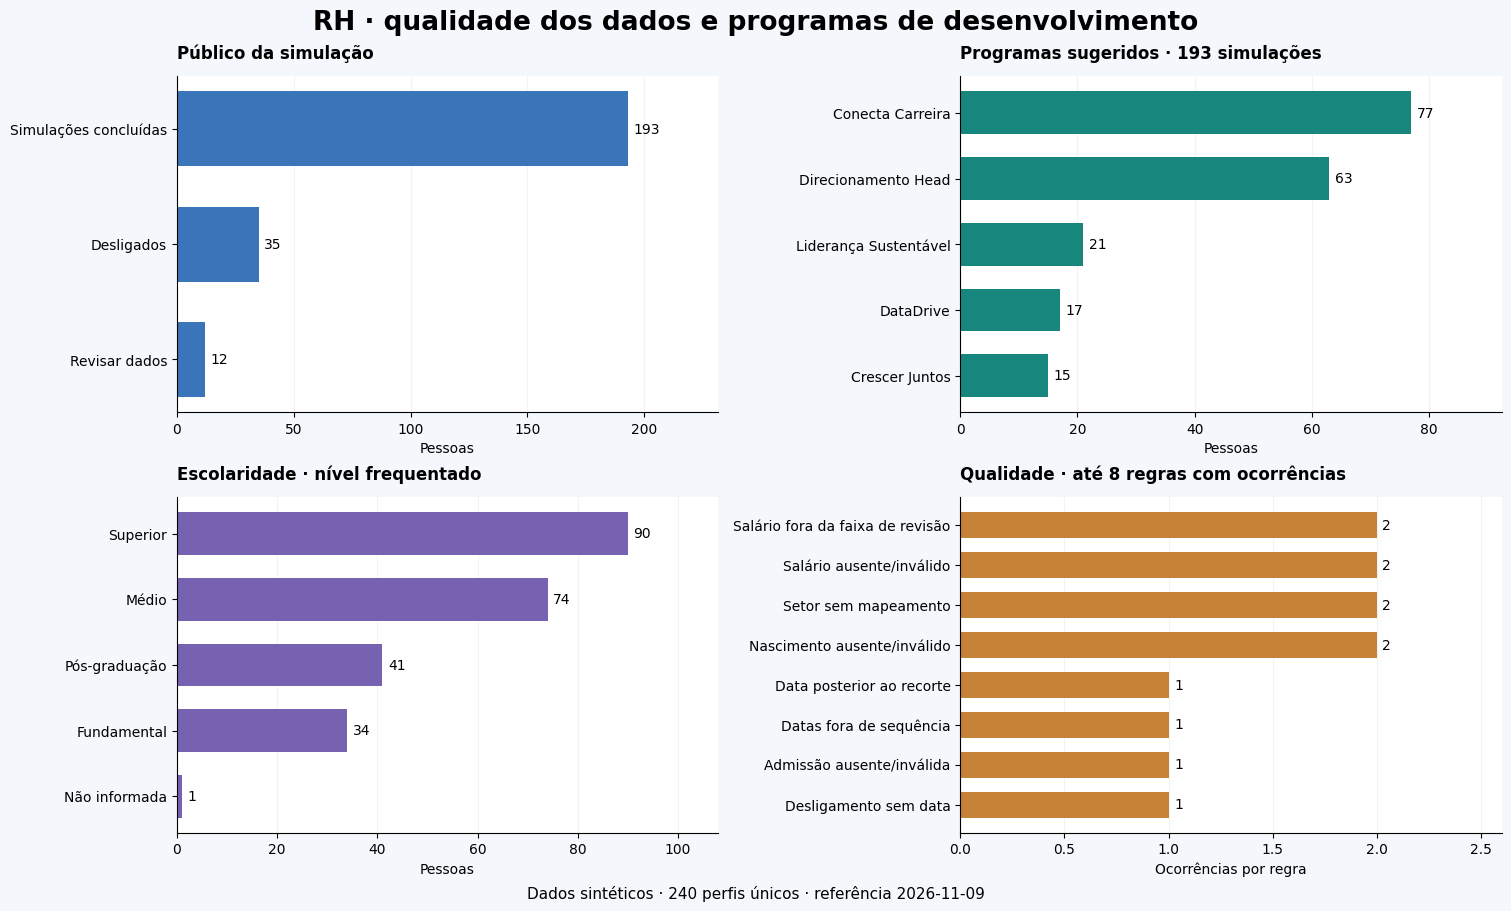

In [7]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': '#f4f7fb',
                     'axes.facecolor': '#ffffff', 'axes.titleweight': 'bold'})
fig, eixos = plt.subplots(2, 2, figsize=(15, 9), layout='constrained')
fig.suptitle('RH · qualidade dos dados e programas de desenvolvimento', fontsize=19, fontweight='bold')
fig.supxlabel(f'Dados sintéticos · {len(tratados)} perfis únicos · referência {DATA_REFERENCIA}', fontsize=11)

publicos = distribuicao_publico.rename(index={
    'Fora do público de demonstração': 'Desligados',
    'Simulação concluída': 'Simulações concluídas',
}).sort_values()
grupos = [
    (publicos, 'Público da simulação', '#3975b8'),
    (simuladas['programa_sugerido'].value_counts().sort_values(),
     f'Programas sugeridos · {len(simuladas)} simulações', '#17877d'),
    (tratados['escolaridade_simplificada'].value_counts().sort_values(),
     'Escolaridade · nível frequentado', '#7662b1'),
]
for eixo, (serie, titulo, cor) in zip(eixos.flat, grupos):
    barras = eixo.barh(serie.index, serie.values, color=cor, height=0.65)
    eixo.bar_label(barras, padding=4, fontsize=10)
    eixo.set_title(titulo, loc='left', pad=13)
    eixo.set_xlabel('Pessoas')
    eixo.set_xlim(0, max(serie.max(), 1) * 1.2)
    eixo.grid(axis='x', alpha=0.15)
    eixo.set_axisbelow(True)

problemas = ocorrencias[ocorrencias.gt(0)].sort_values().tail(8)
nomes = {
    'qualidade_setor': 'Setor sem mapeamento',
    'qualidade_escolaridade': 'Escolaridade a conferir',
    'qualidade_contrato': 'Contrato a conferir',
    'qualidade_situacao': 'Situação desconhecida',
    'qualidade_data_nascimento': 'Nascimento inválido',
    'qualidade_admissao_ausente': 'Admissão ausente/inválida',
    'qualidade_nascimento_ausente': 'Nascimento ausente/inválido',
    'qualidade_desligamento_ausente': 'Desligamento sem data',
    'qualidade_data_futura': 'Data posterior ao recorte',
    'qualidade_cronologia': 'Datas fora de sequência',
    'qualidade_salario': 'Salário ausente/inválido',
    'qualidade_salario_suspeito': 'Salário fora da faixa de revisão',
}
problemas = problemas.rename(index=nomes)
eixo = eixos[1, 1]
barras = eixo.barh(problemas.index, problemas.values, color='#c68236', height=0.65)
eixo.bar_label(barras, padding=4)
eixo.set_title('Qualidade · até 8 regras com ocorrências', loc='left', pad=13)
eixo.set_xlabel('Ocorrências por regra')
eixo.set_xlim(0, max(problemas.max(), 1) * 1.3)
eixo.grid(axis='x', alpha=0.15)
eixo.set_axisbelow(True)

caminho_figura = RAIZ / 'docs/imagens/visao-geral.png'
caminho_figura.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(caminho_figura, dpi=110, facecolor=fig.get_facecolor())
plt.show()

## 5. Pontuação exploratória e limitações

A antiga pontuação de retenção foi renomeada para `pontuacao_perfil_exploratorio`.
Ela combina critérios manuais de tempo de casa, idade, salário, setor, escolaridade e
contrato. Seu intervalo teórico é de 0 a 10 e ela não foi calibrada com resultados de
desligamento. A sugestão de programa usa as pontuações específicas de cada programa.

Para transformar o estudo em uma proposta operacional, RH precisa revisar a finalidade,
o público, os critérios, a ordem dos empates e a diferença entre escolaridade cursada e
concluída. A avaliação de impacto sobre os grupos atendidos faz parte dessa revisão.

O CSV usado no protótipo original já continha valores tratados. O notebook exige a fonte
original para novas cargas e rejeita colunas derivadas de uma execução anterior.
Essa verificação evita reaplicar transformações sobre resultados já modificados.

In [8]:
display(simuladas['pontuacao_perfil_exploratorio'].describe().rename('Pontuação exploratória').to_frame())
display(pd.crosstab(simuladas['setor'], simuladas['programa_sugerido']))

assert resultado.loc[resultado['situacao_vinculo'].eq('Sem vínculo'),
                     'programa_sugerido'].eq('Não simulado').all()
assert simuladas['justificativa'].str.len().gt(0).all()
print('Público e justificativas conferidos.')

,Pontuação exploratória
count,193.000000
mean,5.766839
std,2.321220
min,1.000000
25%,4.000000
50%,7.000000
75%,8.000000
max,10.000000


programa_sugerido,Conecta Carreira,Crescer Juntos,DataDrive,Direcionamento Head,Liderança Sustentável
setor,,,,,
Administrativo,9,0,2,8,0
Comercial,6,0,1,12,0
Compras,5,0,5,0,10
Engenharia / Manutenção,11,4,1,0,3
Financeiro,5,0,0,14,0
Logística,10,6,1,0,2
Marketing,12,0,1,6,0
Produção,5,5,5,0,6
RH,7,0,1,11,0


Público e justificativas conferidos.


## 6. Exportação opcional

`EXPORTAR_RESULTADOS` começa como `False`. Se você ativar o parâmetro, os resultados
sintéticos e o relatório de qualidade serão salvos na pasta local `outputs`, ignorada
pelo Git. A base recebida permanece preservada.

In [9]:
if EXPORTAR_RESULTADOS:
    pasta_saida = RAIZ / 'outputs'
    pasta_saida.mkdir(exist_ok=True)
    resultado.to_csv(pasta_saida / 'rh_programas_sintetico.csv', index=False, encoding='utf-8-sig')
    (pasta_saida / 'qualidade.json').write_text(
        json.dumps(qualidade, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    print('Resultados sintéticos exportados para outputs.')
else:
    print('Exportação opcional desativada. Análise concluída.')

Exportação opcional desativada. Análise concluída.
